2025-10-20
This code takes the _MZdata datafiles (made from Jordan's sorting program and my Jupyter notebook) and makes a new file with the simple average activity score, DNA and AA sequences, and sequence properties.

1. Reads histograms and BC statistics are plotted
2. Simple average of activity is calculated, outliers (>2.6*standard deviation) are excluded and average is recalculated
3. Sequence features are for each AA sequence (Charge, HydrophobicityKD, HydrophobicityWW, Aromatics, WYFL, all #AAs) are added to delta from a seqfeats design file
4. Predictions for each AA sequence are added to delta from a prediction design file
5. Standardized activity is calculated from the controls library
6. Synthetic ADs: columns from old predictions and predictor combos are added; columns renamed
7. delta is saved to .csv at a filepath.

In [1]:
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from scipy import stats

%load_ext autoreload
%autoreload 2

import sys
sys.path.append(r"C:\Users\music\Desktop\CompLab\Global_Scripts")
from Helpful import *

In [2]:
# Edit these variables!

name = 'SynAD_RatioRep_sort1'
name_color = "#f06593"

filetoprocess = r"..\..\data\labtools-processed\SynAD_1_RatioRep_allinfo.csv"
filetosave = rf"..\..\data\{name}_processed.csv"

excludedsaving = True
excludedtosave = rf"..\..\data\excluded\{name}_EXCLUDED.csv"

figsaving = True
if figsaving == True:
    readsfigpath = rf'..\..\output\ProcessingFigs\{name}_Reads_Distributions.png'
    standardizingfigpath = rf'..\..\output\ProcessingFigs\{name}_MachineGaussian.png'
    activityfigpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_Distribution.png'
    gcn4corrpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_corr_Gcn4.png'
    stddevpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_corr_StdDev.png'

negdesign = pd.read_csv(r'C:\Users\music\Desktop\CompLab\DesignFiles\NegControls_Design_AA.csv')

stdsort = pd.read_csv(r"..\..\data\SynAD_Glu_sort2_processed.csv", index_col=0)
stdsort = stdsort[['AAseq', 'StdActivity', 'StdActivityStdDev']]
gcn4sim = pd.read_csv(r'..\..\data\Synth_Gcn4similarseqs.csv')

In [3]:
sort = pd.read_csv(filetoprocess,index_col=0)
sort

,DNAseq,AAseq,BC,Reads,0,1,2,3,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,GTTGCTCCAGCTCAACCAACTTCTGTTGAAAATTCTCCAGAATTGA...,VAPAQPTSVENSPELKSDEVDSDNQSPAPSRRKSGTSPST,TCAAAGGACACTAT,1355.0,1247.0,108.0,0.0,0.0,13784.120187,1.0,3,2629.0
1,TATTTGTGTGATTATTTGCAAATGGGTCCAGATTTTGGTAGAGAAG...,YLCDYLQMGPDFGREAGGAFLLFPWGDSDLAMDDEDGGLY,TAAGTGACTTTATT,1536.0,1130.0,406.0,0.0,0.0,17842.199849,1.0,2,1628.0
2,GTTATTGCTAAAGAAAAAAGAGAAAAAGAAGCTATGAAATTGTTGG...,VIAKEKREKEAMKLLDDENGDFADFDFSDVEIDLGLSLDD,TTGAGACTAGACTA,5952.0,5130.0,819.0,3.0,0.0,15035.269217,1.0,5,11815.0
3,TCTTTGGCTGAATTGGAAAATGAAGGTTTGTTTGATAATGAACATG...,SLAELENEGLFDNEHDDNLEALLPSSSVLTKHPFGFGMFE,ACACATATGAGCAC,1945.0,363.0,1036.0,365.0,181.0,61790.671505,1.0,2,4570.0
4,GATAATTTGATTTGTGATGAATCTGTTTCTGAAGATTTGGAAGGTC...,DNLICDESVSEDLEGQEIELEITPLEVFDDIQKRSDFEVK,AGTCGTCATACTAC,8852.0,8280.0,536.0,34.0,2.0,13659.345470,1.0,5,13545.0
...,...,...,...,...,...,...,...,...,...,...,...,...
45780,ACTGGTTTTACTCCATGGGAATTGAATTGTTCTGATTTGTTTTCTA...,TGFTPWELNCSDLFSIPPLDDHFSDQTPSDDFFDGLEEFA,GCATCATAATAGAA,42.0,0.0,0.0,0.0,42.0,241223.000000,1.0,3,853.0
45781,GAAGAAACTGCTATTTCTAATTGGTGGGAATTTACTGATTCTTGTA...,EETAISNWWEFTDSCINIGFQIPNHNPLSDSEACYAGDNF,TATGGCACGAAGAT,49.0,0.0,0.0,0.0,49.0,241223.000000,1.0,2,676.0
45782,GATGATTTTAAAGGTTTTTTTAATGATGATGATGAATTTGATACTT...,DDFKGFFNDDDEFDTSVYTDDEDDMMMVGDVPWQMFVSSV,TGAAATTAGGAAAT,49.0,0.0,0.0,0.0,49.0,241223.000000,1.0,2,2193.0
45783,GGTGGTTTGTGTTGTTATAGAGAAGTTGGTGATGGTGATCCACAAC...,GGLCCYREVGDGDPQHTFEPSHEIFDELLPPEFDVFMLAM,TCACGGTGAAGACA,91.0,0.0,0.0,0.0,91.0,241223.000000,1.0,3,1072.0


### 1: Reads Figures

C:\Users\music\AppData\Local\Temp\ipykernel_45072\4261927136.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sortsub.drop_duplicates(inplace=True)


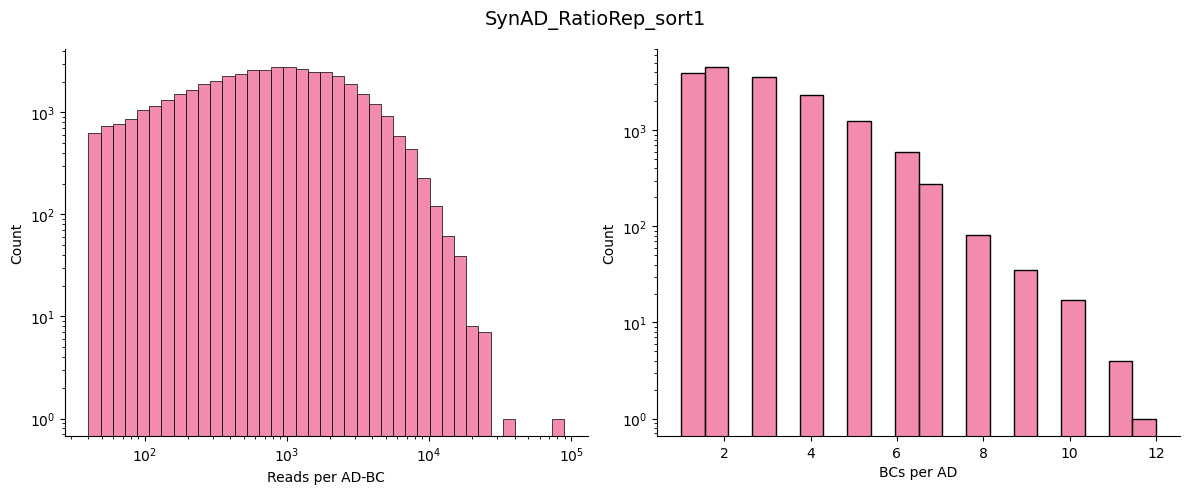

In [5]:
# Create figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Reads (log bins)
minp = sort['Reads'].min()
maxp = sort['Reads'].max()
log_bins = np.logspace(np.log10(minp), np.log10(maxp), 40)



sns.histplot(sort['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0], color=name_color)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Reads per AD-BC')
axes[0].set_ylabel('Count')
sns.despine(ax=axes[0])

# Plot 2: BCs per AD
sortsub = sort[['AAseq', 'ADs_per_BC', "BCs_per_AD"]]
sortsub.drop_duplicates(inplace=True)

sns.histplot(sortsub['BCs_per_AD'], bins=20, ax=axes[1], color=name_color)
axes[1].set_yscale('log')
axes[1].set_xlabel('BCs per AD')
axes[1].set_ylabel('Count')
sns.despine(ax=axes[1])

plt.suptitle(name, fontsize=14)
plt.tight_layout()
plt.show()

if figsaving:
    fig.savefig(readsfigpath, dpi=300)

### 2: Calculating Average Activity per AAseq

In [5]:
help(simple_average_minus_outliers)

Help on function simple_average_minus_outliers in module Helpful:

simple_average_minus_outliers(df, aa_col: str = 'AAseq', activity_col: str = 'Activity', min_reps_for_std: int = 2, ddof: int = 1, thresh: float = 2.6)
    Calculate simple averages per-group, remove outliers, and recompute.

    Minimal, explicit behavior:
    - Groups by `aa_col` and collects replicate values from `activity_col`.
    - Raises ValueError if any replicate value cannot be converted to float.
    - Uses `remove_outliers` with the provided `thresh` to decide exclusions.

    Returns (included_df, excluded_df) where included_df has one row per group and
    excluded_df has one row per original excluded replicate.



In [7]:
delta, excluded_df = simple_average_minus_outliers(sort, min_reps_for_std=2, ddof=1, thresh=2.6)
delta

,AAseq,Activity,StdDev,NumReps,OriginalIndices,ReplicateActivities
0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,26508.193343,NaN,1,[12226],[26508.19334255188]
1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,53215.398233,NaN,1,[19093],[53215.39823291105]
2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,147266.471781,16324.334661,4,"[19035, 28410, 33504, 34919]","[124032.79661279327, 153999.9981249251, 149264..."
3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,108575.069762,5068.622663,3,"[13312, 20772, 27806]","[102954.57922056357, 109971.63180985916, 11279..."
4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,39235.766836,NaN,1,[18215],[39235.7668361443]
...,...,...,...,...,...,...
16613,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,235324.705696,8950.338986,3,"[24342, 24815, 44089]","[225025.9897677249, 239725.127320646, 241223.0]"
16614,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,205592.605640,50388.986936,2,"[41889, 44424]","[169962.21128081728, 241223.0]"
16615,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,19574.388793,NaN,1,[4997],[19574.388793414204]
16616,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,121662.427934,10249.824778,2,"[21368, 30488]","[128910.14854013284, 114414.70732727813]"


In [8]:
excluded_df

,AAseq,OriginalIndex,FilteredOutActivity,ReplicateActivities,SimpleAverageBefore,SimpleAverageAfter,SimpleStdDevBefore,SimpleStdDevAfter
0,DDFDDITSEFLQVEGESSSSSFSFDAFPLPNNNQEVLDLR,33023,123941.067398,"[72892.01419344795, 56304.28086572282, 71821.3...",71210.746223,65351.821648,19361.058335,5960.552330
1,MECVEAFLGDFSVDDFSVDDFSVDDFSVDDFSVDDLLVDY,42137,234600.883336,"[239643.3144320379, 240889.05423848095, 239285...",240301.294682,240819.513896,1911.592371,689.005596


### 5: Standardized activity

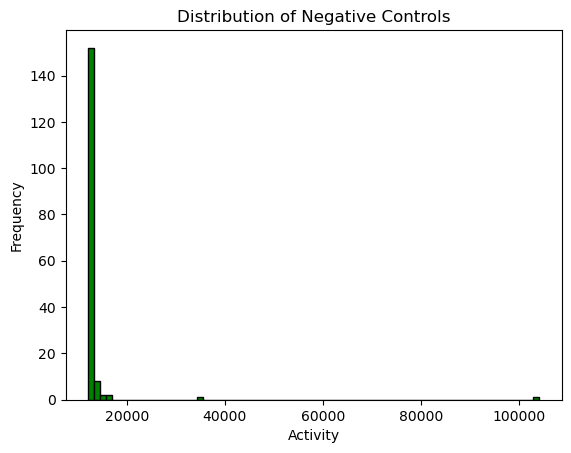

In [9]:
negctrls = delta[delta['AAseq'].isin(negdesign['AAseq'])][['AAseq', 'Activity']]
gcn4 = delta[delta['AAseq'] == 'METFEESSDLDVIRDVDLNKIEPWDIQELCGYDQNQNQFE']['Activity'].values[0]
gcn4s = delta[delta['AAseq'].isin(gcn4sim['AAseq'])]['Activity'].mean()
# ^this/these sequence(s) has(ve) very similar activity to Gcn4, and low StdDev in Glu sort

plt.hist(data=negctrls, x="Activity",bins=75, edgecolor='black',linewidth=1, color='green')
# Add labels and title
plt.xlabel("Activity")
plt.ylabel("Frequency")
plt.title("Distribution of Negative Controls")
# Show plot
plt.show()
# else:
#     # Change this 'lowact' threshold until the machine noise peak is obvious
#     lowact = delta['Activity'].quantile(0.03)
#     lowdelta = delta[delta['Activity'] < lowact]

#     plt.hist(data=lowdelta, x="Activity",bins=75, edgecolor='black',linewidth=1)
#     # Add labels and title
#     plt.xlabel("Activity")
#     plt.ylabel("Frequency")
#     plt.title("Distribution of Low Activity Sequences")
#     # Show plot
#     plt.show()

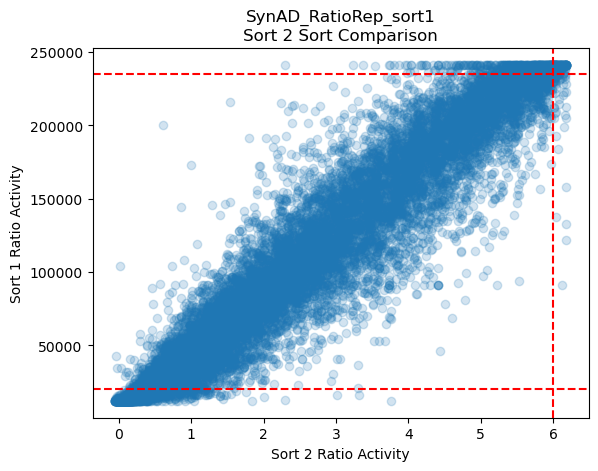

In [16]:
cutoff_top = 235000
cutoff_bottom = 20000
stdsort_cutoff_top = 6
merge = pd.merge(stdsort, delta, on='AAseq', how='inner')
plt.scatter(merge['StdActivity'], merge[f'Activity'], alpha=0.2)
plt.axhline(y=cutoff_top, color='r', linestyle='--')
plt.axhline(y=cutoff_bottom, color='r', linestyle='--')
plt.axvline(x=stdsort_cutoff_top, color='r', linestyle='--')
plt.title(f'{name}\nSort 2 Sort Comparison')
plt.ylabel(f'Sort 1 Ratio Activity')
plt.xlabel(f'Sort 2 Ratio Activity')
plt.show()

Fit equation: y = 38902.325 x + 7861.148


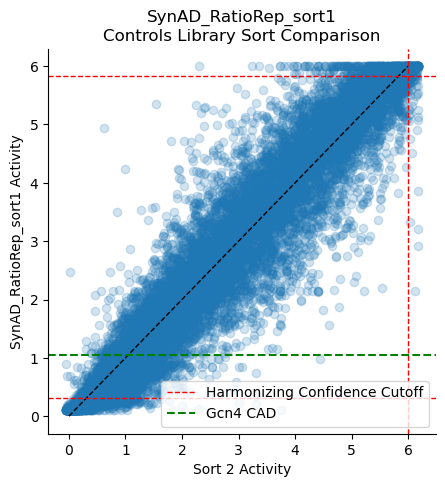

In [17]:
mergesub = merge[merge[f'Activity'] < cutoff_top]
mergesub = mergesub[mergesub[f'Activity'] > cutoff_bottom]
mergesub = mergesub[mergesub['StdActivity'] < stdsort_cutoff_top]
# fit
x = mergesub['StdActivity']
y = mergesub[f'Activity']
slope, intercept, r_value, p_value, stderr = stats.linregress(mergesub['StdActivity'], mergesub[f'Activity'])
print(f'Fit equation: y = {slope:.3f} x + {intercept:.3f}')

# Inverse mapping: sort_activity -> StdActivity
def standardize(y_vals, slope=slope, intercept=intercept):
    """
    Convert sort activity (y) to StdActivity using the inverse of fitted line:
        Std = (y - intercept) / slope
    Returns np.ndarray of floats. If slope ~ 0 returns NaNs.
    """
    y_arr = np.asarray(y_vals, dtype=float)
    if np.isclose(slope, 0): # avoid divide by zero if slope is 0
        return np.full(y_arr.shape, np.nan, dtype=float)
    std = (y_arr - intercept) / slope
    return std

# Apply mapping to full gcn4sort (adds new column)
x_new = merge['StdActivity']
y_new = standardize(merge[f'Activity'].values)
std_cutoff_top = standardize(cutoff_top)
std_cutoff_bottomr = standardize(cutoff_bottom)
std_gcn4 = standardize(gcn4)
std_gcn4s = standardize(gcn4s)

# plot
fig, ax = plt.subplots(figsize=(5,5))
ax.plot([0,y_new.max()],[0,y_new.max()], 'k--', lw=1)
ax.axhline(y=std_cutoff_top, color='r', linestyle='--', lw=1, label='Harmonizing Confidence Cutoff')
ax.axhline(y=std_cutoff_bottomr, color='r', linestyle='--', lw=1)
ax.axvline(x=stdsort_cutoff_top, color='r', linestyle='--', lw=1)
ax.axhline(y=std_gcn4, color='g', linestyle='--', label='Gcn4 CAD')
ax.scatter(x_new, y_new, alpha=0.2)
ax.set_title(f'{name}\nControls Library Sort Comparison')
ax.set_ylabel(f'{name} Activity')
ax.set_xlabel(f'Sort 2 Activity')
ax.legend()
sns.despine(ax=ax)
plt.show()

SynAD_RatioRep_sort1: StdAct 0 = 7861.15 in FACS Activity; StdAct 1 (Gcn4) = 46763.47 in FACS Activity


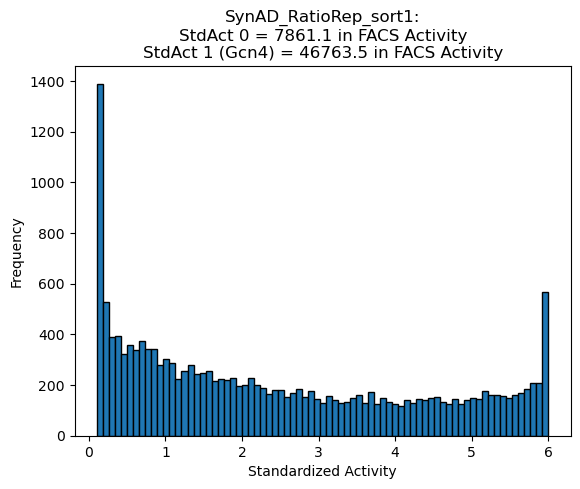

In [18]:
print(f'{name}: StdAct 0 = {(0*slope + intercept):.2f} in FACS Activity; StdAct 1 (Gcn4) = {1*slope + intercept:.2f} in FACS Activity')

# Apply the scaling function to the 'Activity' column
delta['StdActivity'] = standardize(delta['Activity'].values)
delta['ReplicateStdActivities'] = delta['ReplicateActivities'].apply(
    lambda activities: [standardize(activity, slope=slope, intercept=intercept) for activity in activities]
)

plt.hist(data=delta, x="StdActivity",bins=75, edgecolor='black',linewidth=1)

# Add labels and title
plt.xlabel("Standardized Activity")
plt.ylabel("Frequency")
plt.title(f"{name}:\nStdAct 0 = {(0*slope + intercept):.1f} in FACS Activity\nStdAct 1 (Gcn4) = {(1*slope + intercept):.1f} in FACS Activity")

# Show plot
plt.show()

In [19]:
# Define a function to calculate the standard deviation or return NaN
def calculate_stddev(activity_list):
    if len(activity_list) >= 2:
        return np.std(activity_list)
    else:
        return np.nan

# Apply the function to the 'ReplicateStdActivities' column
delta['StdActivityStdDev'] = delta['ReplicateStdActivities'].apply(calculate_stddev)

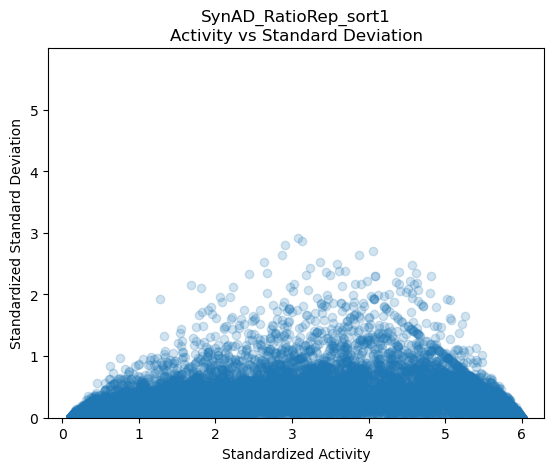

In [20]:
plt.scatter(delta['StdActivity'], delta['StdActivityStdDev'], alpha=0.2)
plt.ylim(0, max(delta['StdActivity']))
plt.title(f'{name}\nActivity vs Standard Deviation')
plt.xlabel('Standardized Activity')
plt.ylabel('Standardized Standard Deviation')
if figsaving:
    plt.savefig(stddevpath, dpi=300)
plt.show()

### 8: Saving data

In [21]:
delta.to_csv(filetosave)

In [22]:
if excludedsaving == True:
    excluded_df.to_csv(excludedtosave)

### 9: Extras